# 01 - Semantic axes

In our paper *How Far Is Too Far?*, we use ImageNet-OOC1k to study how object recognition changes when objects are placed in increasingly unrelated backgrounds.

To create these pairings, we need a way to measure how closely an object class relates to a background. For this, we define a semantic axis that lets us control the compositions and measure recognition accuracy as a function of the semantic distance between the background and the added object.

We first look at the unembedding matrices of individual models and the relationships between ImageNet classes encoded in their weights. We then combine the dissimilarity matrices from ten models into the consensus visual-semantic axis used in the paper and look at a few class neighbourhoods.

In [ ]:
import json
import os
from pathlib import Path

# Repository paths
REPO_ROOT = Path.cwd()
DATA_DIR = REPO_ROOT / "data"
OUTPUT_DIR = REPO_ROOT / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# All semantic axes are saved here and used by the later notebooks
SEMANTIC_AXES_DIR = DATA_DIR / "semantic_axes"
HEADS_DIR = SEMANTIC_AXES_DIR / "individual_heads"
HEADS_DIR.mkdir(parents=True, exist_ok=True)

# Model weight caches (set these before importing timm). None keeps the default caches in your
# home folder; set a path if you want the weights on a bigger disk.
CACHE_DIR = None
if CACHE_DIR is not None:
    os.environ["HF_HOME"] = str(CACHE_DIR / "hf_cache")
    os.environ["TORCH_HOME"] = str(CACHE_DIR / "torch_cache")
CLIP_DOWNLOAD_ROOT = None if CACHE_DIR is None else str(CACHE_DIR / "cache" / "clip")

In [2]:
import clip
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from timm import create_model

# Plotting functions live outside the notebook to keep it readable.
from ooc1k.plotting.a_semantic_axis import (plot_dissimilarity_matrices, plot_rdm_with_dendrograms)

# Load the ImageNet class index and extract the names used to label the plots.
with open(REPO_ROOT / "helper_files" / "imagenet_class_index.json") as f:
    class_index = json.load(f)

CLASS_LABELS = [class_index[str(i)][1] for i in range(1000)]

/pfss/mlde/workspaces/mlde_wsp_PI_Roig/bersch/conda/envs/ooc/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Single-model dissimilarity matrices

Here, we look at the relationships between ImageNet classes encoded in individual models. Each row of the **unembedding matrix** contains the classifier weights for one class, which we treat as a class prototype. We compare these prototypes using cosine dissimilarity (`1 - cos`, Eq. 1) to see which classes are represented similarly and how these relationships differ across models.

For CLIP, which has no ImageNet classifier head, we compare text embeddings of `"a photo of a {class}"` instead.


In [3]:
def symmetrise(D):
    """Average a matrix with its transpose to remove rounding asymmetries, and zero the diagonal."""
    D = (D + D.T) / 2
    np.fill_diagonal(D, 0.0)
    return D


def get_dissimilarity_from_weights(model):
    """
    Extract classifier head weights and compute pairwise cosine dissimilarity.

    Steps:
        1. Find the final linear layer (head / fc / classifier / last Linear module).
        2. L2-normalise the rows (one row = one class embedding).
        3. Compute cosine similarity via matrix multiply, convert to dissimilarity.
        4. Symmetrise and set the diagonal to zero.

    Returns:
        np.ndarray of shape (1000, 1000), values in [0, 2].
    """
    model.eval()
    if hasattr(model, "head"):
        W = model.head.weight.detach()
    elif hasattr(model, "fc"):
        W = model.fc.weight.detach()
    elif hasattr(model, "classifier"):
        W = model.classifier.weight.detach()
    else:
        W = [m for m in model.modules() if isinstance(m, torch.nn.Linear)][-1].weight.detach()

    W_norm = F.normalize(W.float(), dim=1)
    return symmetrise((1 - W_norm @ W_norm.T).cpu().numpy())


def get_dissimilarity_from_clip(clip_model, class_labels, prompt_template):
    """
    Build a dissimilarity matrix from CLIP text embeddings of class names.

    Steps:
        1. Format each label with the prompt template.
        2. Tokenise and encode all prompts through the CLIP text encoder.
        3. L2-normalise embeddings, compute pairwise cosine dissimilarity.
        4. Symmetrise and set the diagonal to zero.

    Returns:
        np.ndarray of shape (1000, 1000), values in [0, 2].
    """
    clip_model.eval()
    tokens = clip.tokenize([prompt_template.format(label) for label in class_labels])
    with torch.no_grad():
        text_features = clip_model.encode_text(tokens.to(next(clip_model.parameters()).device))

    text_features = F.normalize(text_features.float(), dim=1)
    return symmetrise((1 - text_features @ text_features.T).cpu().numpy())

In [ ]:
# The ten consensus models (see below) and DeiT-B/16, one of the main models of the paper.
HEAD_MODELS = [
    "vit_base_patch16_224",
    "vit_small_patch16_224",
    "vit_large_patch16_224",
    "vit_base_patch32_224",
    "vit_base_patch16_384",
    "resnet50",
    "resnet101",
    "efficientnet_b3",
    "efficientnet_b5",
    "densenet121",
    "deit_base_patch16_224",
]
CLIP_MODEL = "ViT-B/16"
CLIP_PROMPT_TEMPLATE = "a photo of a {}"

# Compare the ImageNet class prototypes in each classifier head and save every matrix.
heads = {}
for model_name in HEAD_MODELS:
    heads[model_name] = get_dissimilarity_from_weights(create_model(model_name, pretrained=True))
    np.save(HEADS_DIR / f"{model_name}.npy", heads[model_name])

# CLIP needs to be loaded slightly differently
clip_model, _ = clip.load(
    CLIP_MODEL,
    device="cpu",
    download_root=CLIP_DOWNLOAD_ROOT,
)
clip_text = get_dissimilarity_from_clip(clip_model, CLASS_LABELS, CLIP_PROMPT_TEMPLATE)
np.save(SEMANTIC_AXES_DIR / "clip_text.npy", clip_text)
print(f"Saved {len(heads)} classifier heads to {HEADS_DIR} and the CLIP text matrix to {SEMANTIC_AXES_DIR}")

single_matrices = {
    "ViT-B/16": heads["vit_base_patch16_224"],
    "ResNet-50": heads["resnet50"],
    "EfficientNet-B3": heads["efficientnet_b3"],
    "CLIP Text Encoder": clip_text,
}
fig = plot_dissimilarity_matrices(single_matrices)
plt.show()

## Consensus visual-semantic axis

The matrices above share some structure, but the relationships between classes also differ across models. This is expected, given their different architectures and training. To avoid basing our experiments on a single model, we build a consensus matrix from **five ViTs and five CNNs**.

We take the classifier-head matrices of these ten models from above. We then z-score the off-diagonal values, average and symmetrise the matrices, and rescale the off-diagonal values to [0, 1]. The diagonal is set to zero.

We call this the **consensus visual-semantic axis**: it captures how visual classifiers organise the ImageNet classes, not semantic similarity in a linguistic or taxonomic sense (compare the CLIP text and WordNet axes, and notebook 08).

In [5]:
def build_consensus(matrices):
    """
    Consensus of several dissimilarity matrices.

    Steps:
        1. Z-score normalise each matrix (off-diagonal only).
        2. Average and symmetrise.
        3. Min-max rescale the off-diagonal to [0, 1], zero diagonal.

    Returns:
        np.ndarray of shape (1000, 1000).
    """
    mask = ~np.eye(matrices[0].shape[0], dtype=bool)

    z_matrices = []
    for D in matrices:
        vals = D[mask]
        Z = D.copy()
        Z[mask] = (D[mask] - vals.mean()) / vals.std()
        z_matrices.append(Z)

    consensus = np.mean(np.stack(z_matrices), axis=0)
    consensus = (consensus + consensus.T) / 2

    off_diag = consensus[mask]
    consensus[mask] = (consensus[mask] - off_diag.min()) / (off_diag.max() - off_diag.min())
    np.fill_diagonal(consensus, 0.0)
    return consensus

Mean dissimilarity: 0.863
Standard deviation: 0.053
Saved to /pfss/mlde/workspaces/mlde_wsp_PI_Roig/bersch/repositories/OOC-Dataset-Creator/imagenet-ooc1k/data/semantic_axes/consensus.npy


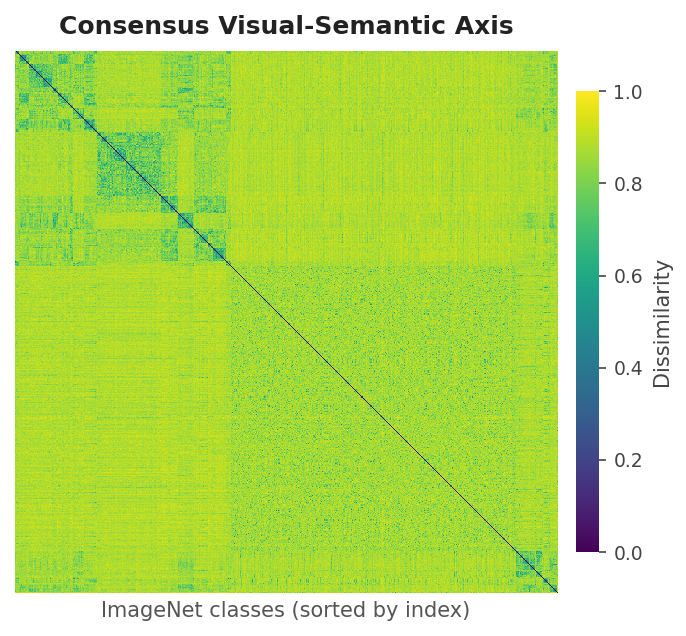

In [6]:
# Five ViTs and five CNNs contribute to the consensus.
CONSENSUS_MODELS = [
    "vit_base_patch16_224",
    "vit_small_patch16_224",
    "vit_large_patch16_224",
    "vit_base_patch32_224",
    "vit_base_patch16_384",
    "resnet50",
    "resnet101",
    "efficientnet_b3",
    "efficientnet_b5",
    "densenet121",
]
CONSENSUS_PATH = SEMANTIC_AXES_DIR / "consensus.npy"

consensus = build_consensus([heads[name] for name in CONSENSUS_MODELS])

off_diagonal = consensus[~np.eye(consensus.shape[0], dtype=bool)]
print(f"Mean dissimilarity: {off_diagonal.mean():.3f}")
print(f"Standard deviation: {off_diagonal.std():.3f}")

np.save(CONSENSUS_PATH, consensus)
print(f"Saved to {CONSENSUS_PATH}")


fig = plot_dissimilarity_matrices({"Consensus Visual-Semantic Axis": consensus})
plt.show()

## Semantic neighbourhoods

Here, we take a closer look at the class relationships in each matrix, including the consensus. For each focal class, we select its 15 nearest neighbours and group them into a dendrogram using hierarchical clustering. This makes the local structure easier to inspect visually to get an intuition about how the models encode the classes.

Related classes often cluster together. For the ImageNet classifiers, this is interesting because they were trained to recognise classes, without an explicit objective to arrange them into semantic groups.

Set `SHOW_MATRIX = False` to plot only the dendrograms, without the matrix next to them.

Try changing `FOCAL_CLASSES` to other names from `CLASS_LABELS` and see how their neighbourhoods differ across models.

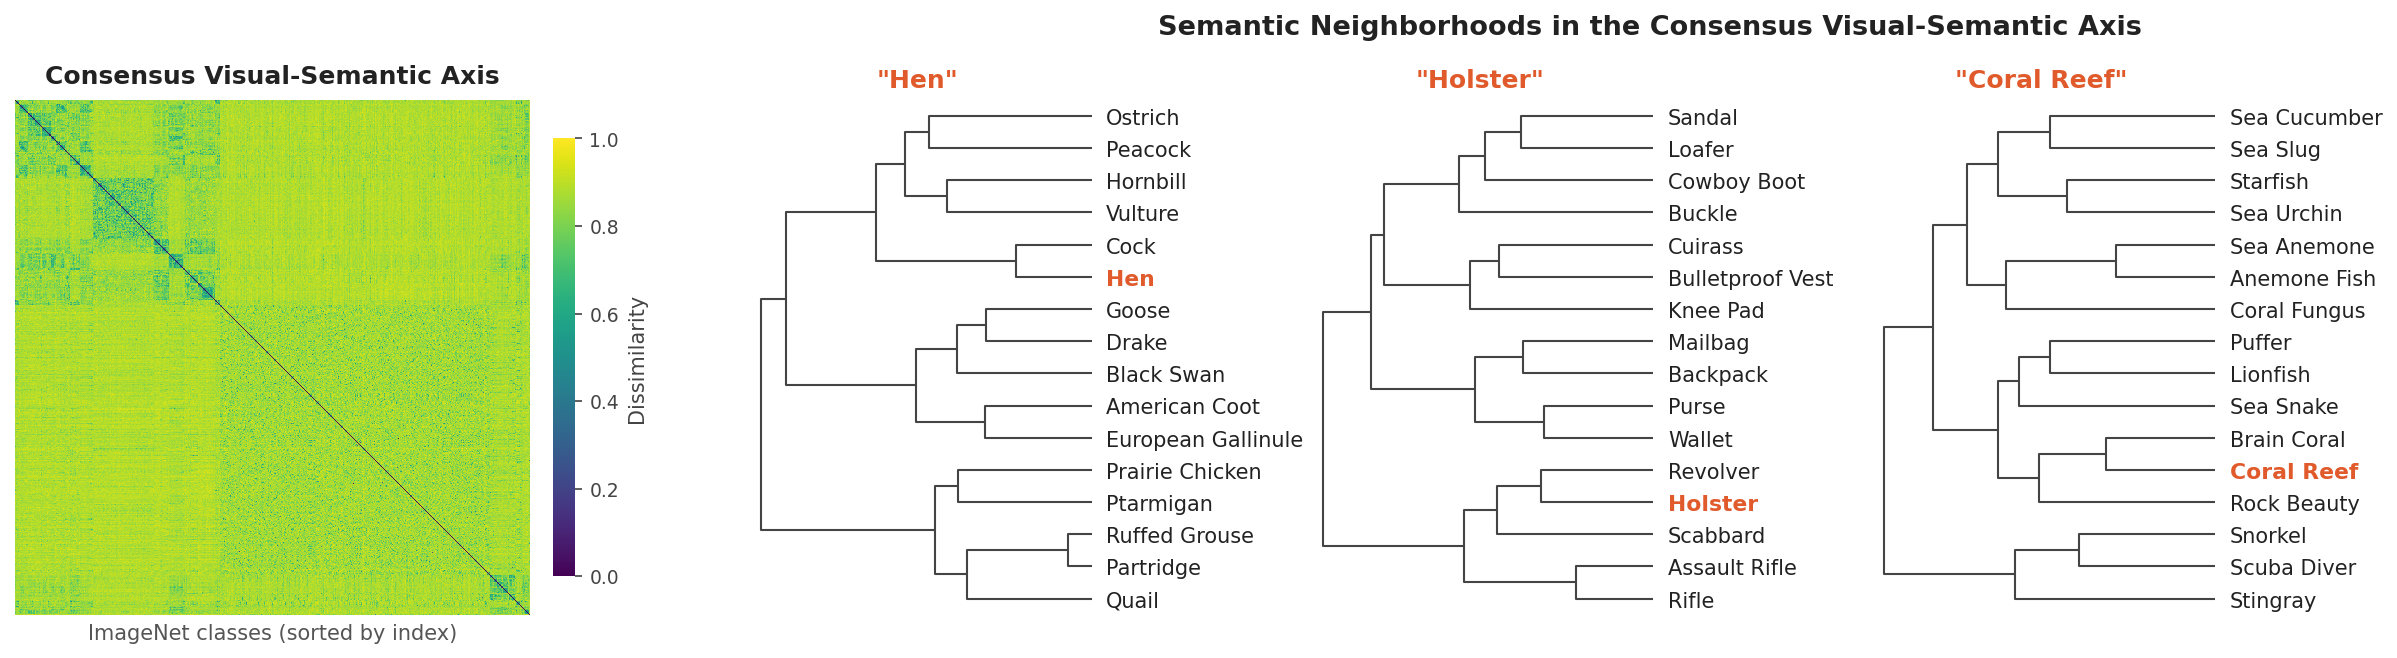

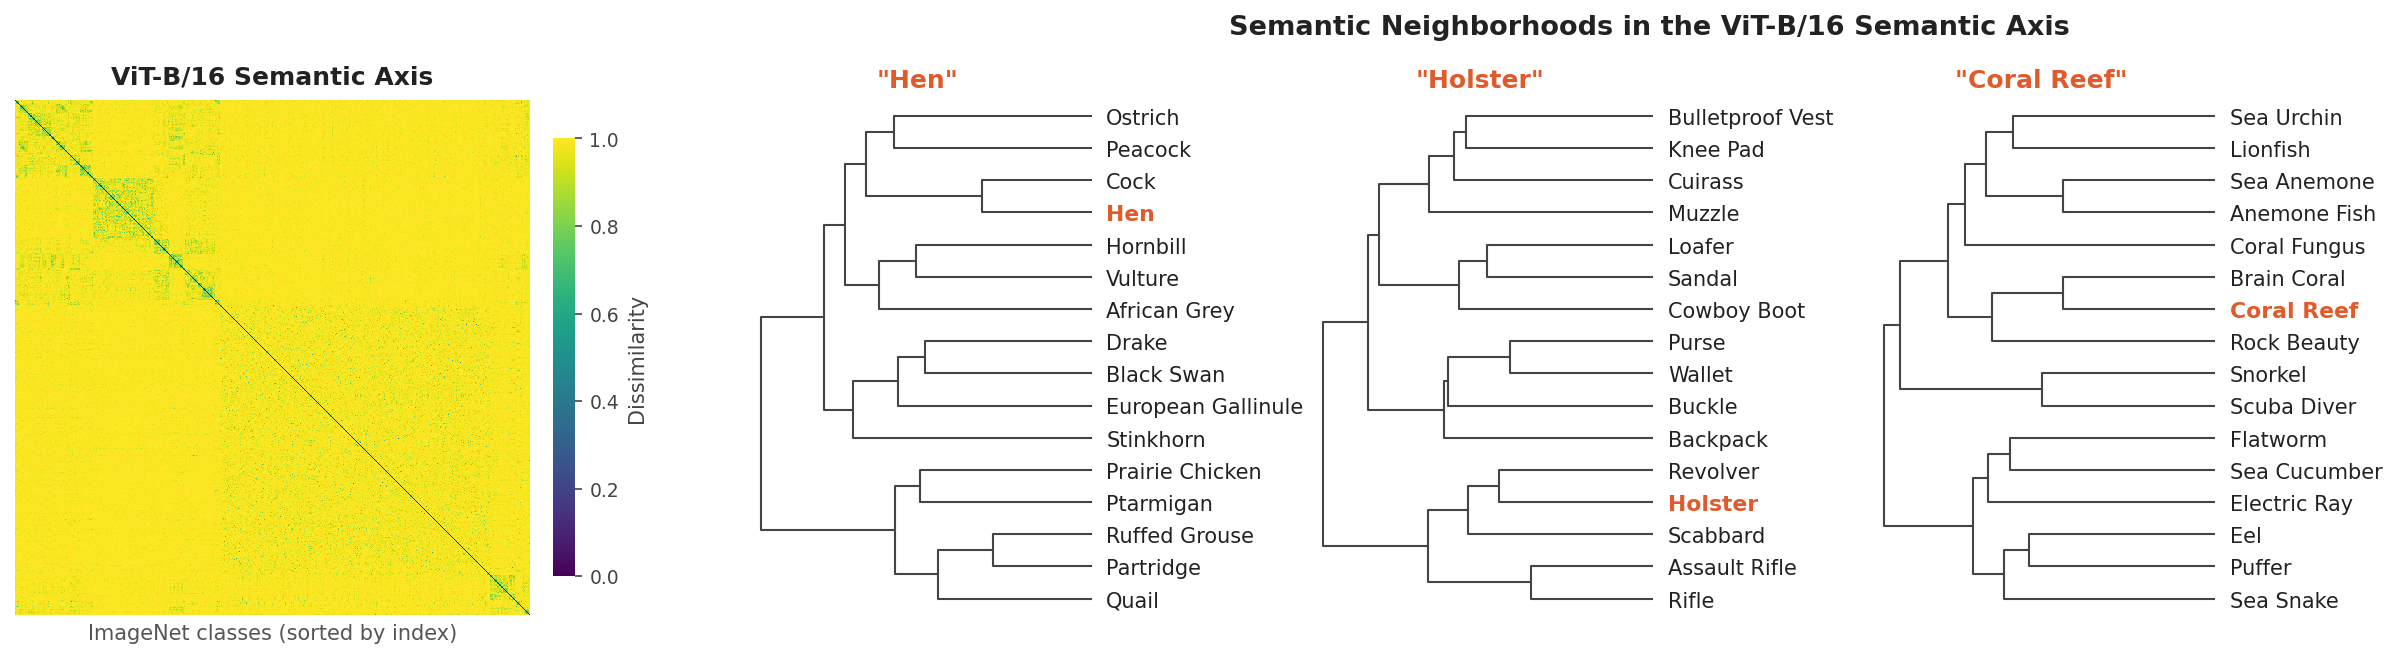

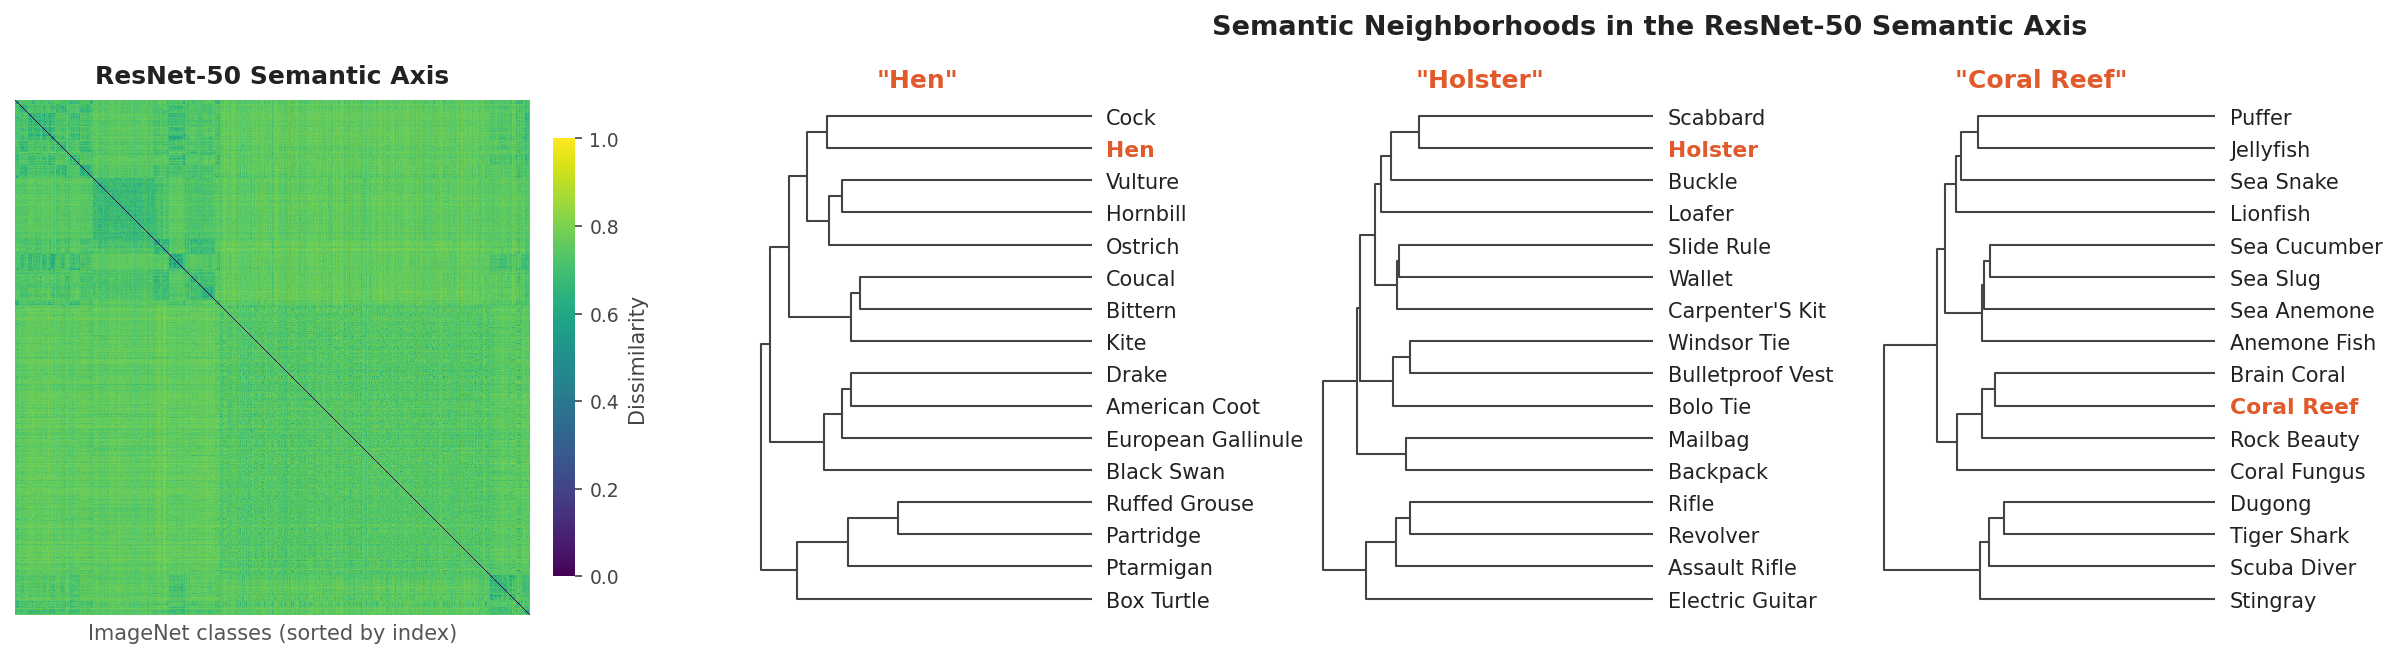

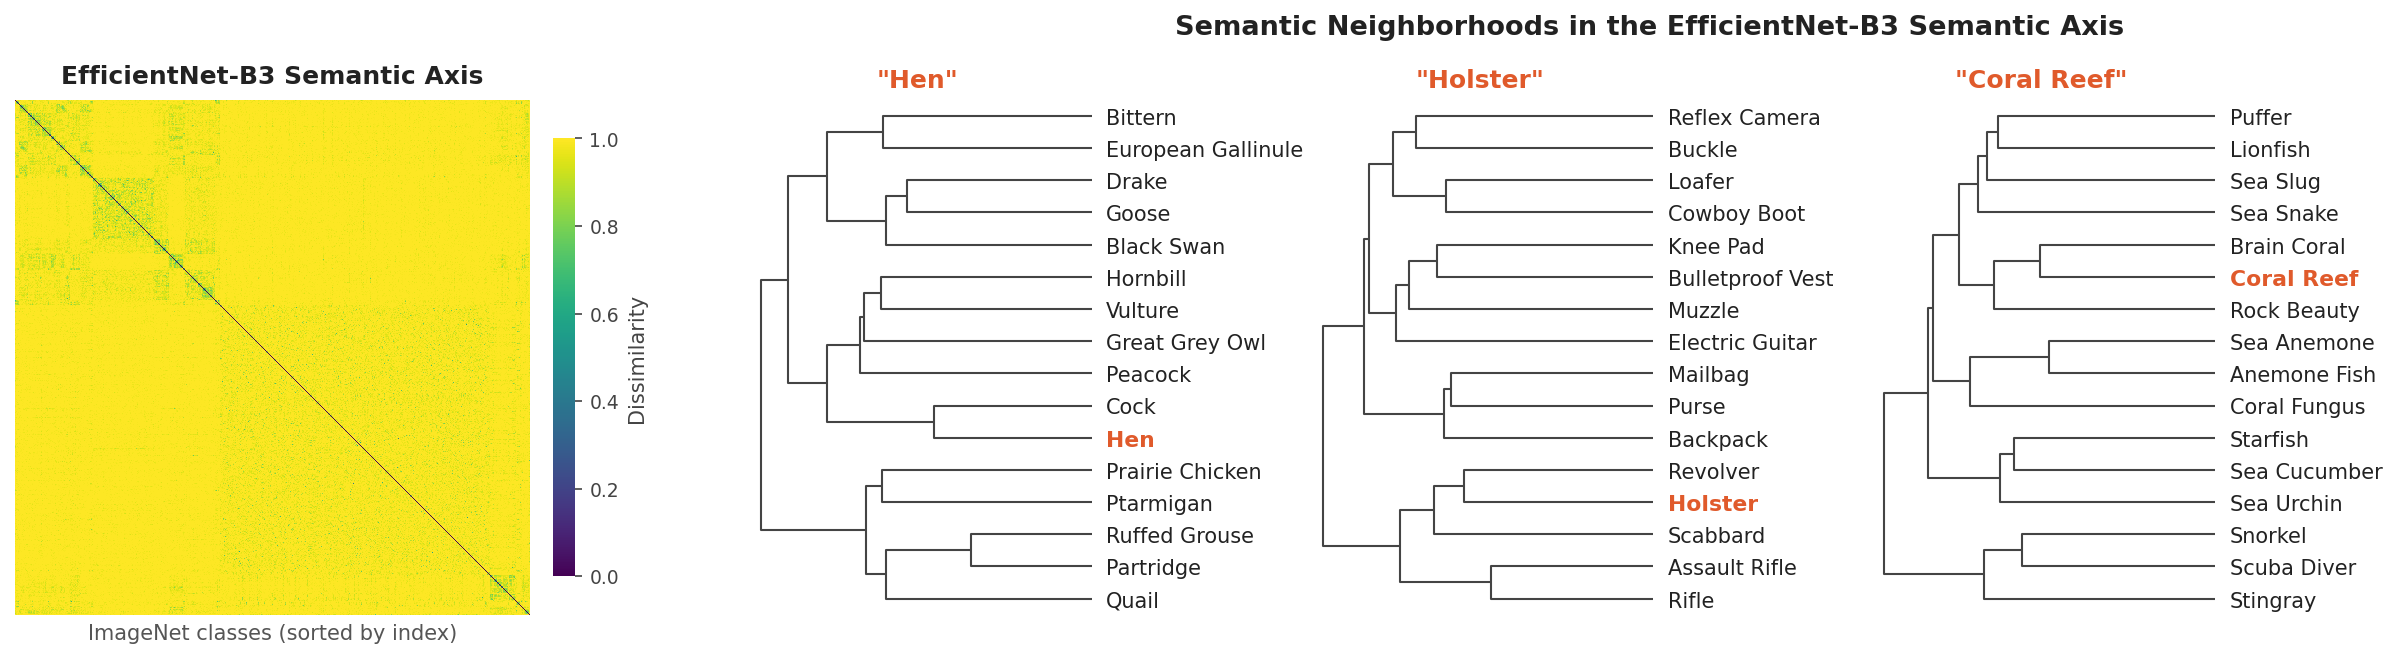

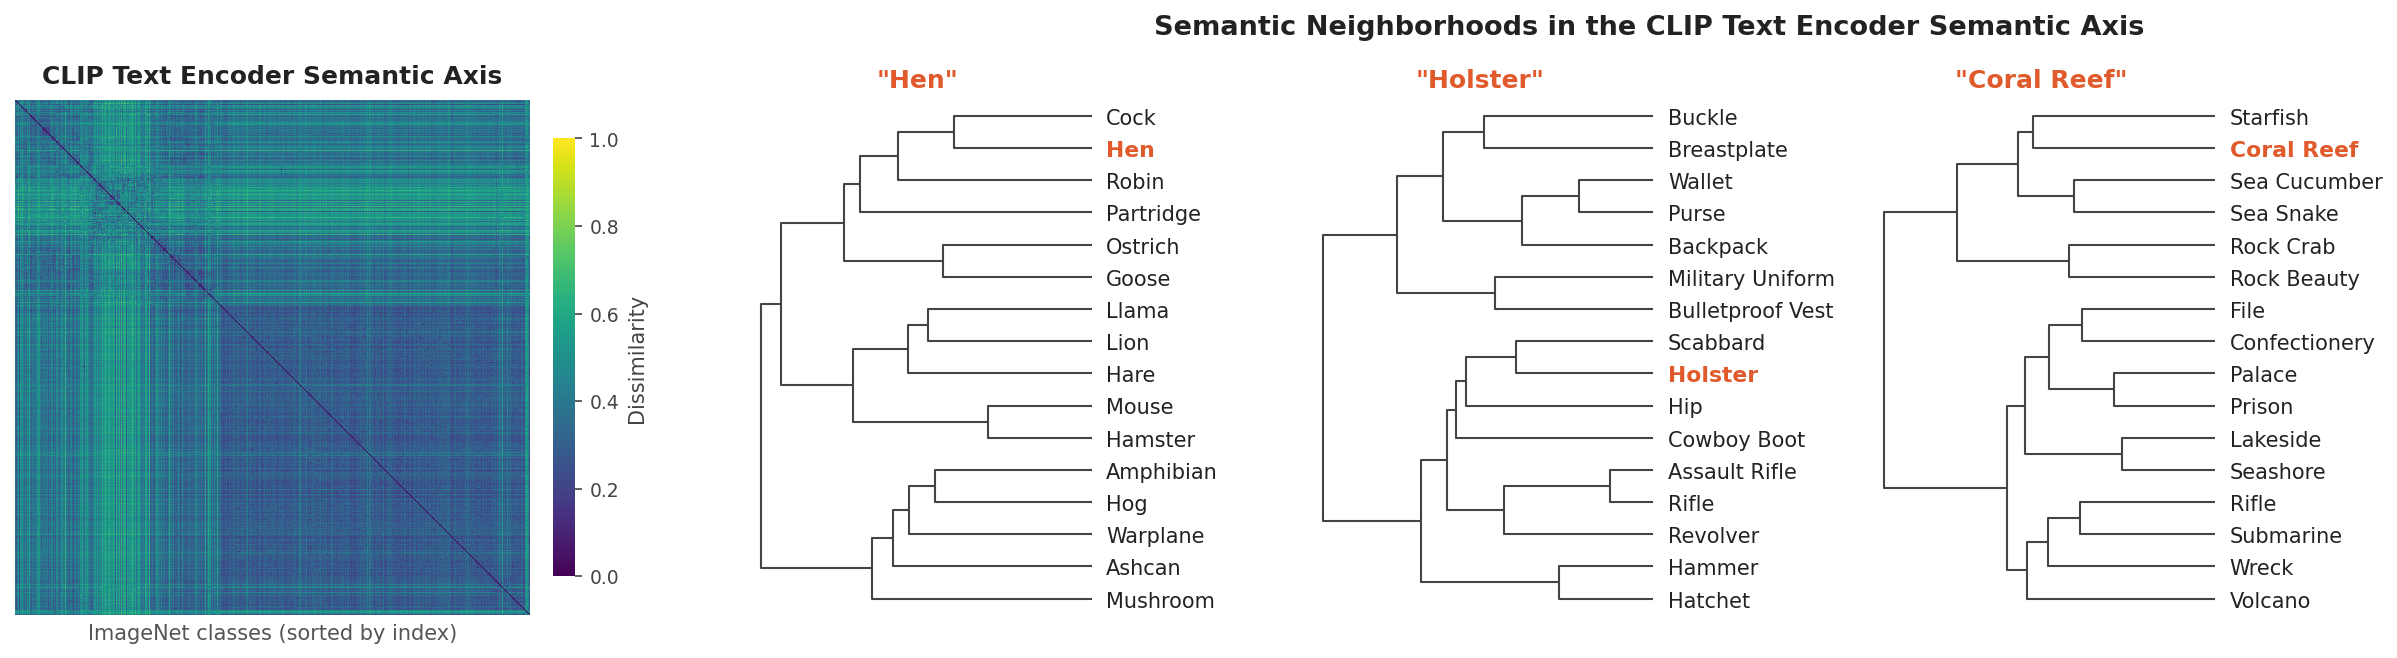

In [11]:
FOCAL_CLASSES = ["hen", "holster", "coral_reef"]
SHOW_MATRIX = True        # False: only the dendrograms, saved with the suffix "_dendrograms"

figures = {
    "consensus": ("Consensus Visual-Semantic Axis", consensus),
    "vit_b16": ("ViT-B/16 Semantic Axis", single_matrices["ViT-B/16"]),
    "resnet50": ("ResNet-50 Semantic Axis", single_matrices["ResNet-50"]),
    "efficientnet_b3": ("EfficientNet-B3 Semantic Axis", single_matrices["EfficientNet-B3"]),
    "clip_text": ("CLIP Text Encoder Semantic Axis", single_matrices["CLIP Text Encoder"]),
}
suffix = "" if SHOW_MATRIX else "_dendrograms"

for file_name, (title, matrix) in figures.items():
    fig = plot_rdm_with_dendrograms(matrix, title, CLASS_LABELS, FOCAL_CLASSES, show_matrix=SHOW_MATRIX)
    fig.savefig(FIG_DIR / f"{file_name}{suffix}.pdf", bbox_inches="tight", dpi=300)
    fig.savefig(FIG_DIR / f"{file_name}{suffix}.png", bbox_inches="tight", dpi=300)
    plt.show()

## WordNet axis

In notebook 05, we check whether the decline in accuracy depends on how we define semantic distance. Besides the single classifier heads and the CLIP text encoder from above, we also compare with a definition that has nothing to do with images: **WordNet**.

WordNet is a lexical database of English in which nouns are organised in a hierarchy of "is-a" relations: a hen is a chicken, which is a bird, ..., which is an animal. The ImageNet classes are taken directly from this hierarchy, and their IDs (e.g. `n01514859` for hen) are the positions of the classes in WordNet. For every pair of classes, we count the number of steps (hops) along the hierarchy on the shortest path between them. As for the consensus, we then rescale the off-diagonal values to [0, 1] and set the diagonal to zero.

Computing the 499,500 class pairs takes a few minutes.

In [8]:
import nltk
from nltk.corpus import wordnet as wn

nltk.download("wordnet", quiet=True)
WORDNET_PATH = SEMANTIC_AXES_DIR / "wordnet.npy"

# The ImageNet class IDs are WordNet noun IDs, e.g. n01514859 -> noun 1514859.
synsets = [wn.synset_from_pos_and_offset(wnid[0], int(wnid[1:])) for wnid, _ in (class_index[str(i)] for i in range(1000))]

# Number of hops on the shortest path between every pair of classes.
hops = np.zeros((1000, 1000))
for i in range(1000):
    for j in range(i + 1, 1000):
        hops[i, j] = hops[j, i] = synsets[i].shortest_path_distance(synsets[j])

# Rescale the off-diagonal values to [0, 1], as for the consensus.
mask = ~np.eye(1000, dtype=bool)
wordnet = np.zeros_like(hops)
wordnet[mask] = (hops[mask] - hops[mask].min()) / (hops[mask].max() - hops[mask].min())

np.save(WORDNET_PATH, wordnet)
print(f"Hops between two classes: {hops[mask].min():.0f} to {hops[mask].max():.0f}")
print(f"Saved to {WORDNET_PATH}")

Hops between two classes: 2 to 26
Saved to /pfss/mlde/workspaces/mlde_wsp_PI_Roig/bersch/repositories/OOC-Dataset-Creator/imagenet-ooc1k/data/semantic_axes/wordnet.npy


For a first impression, here are a few hop counts from the hen. Classes in the same branch of the hierarchy are only a few hops apart, unrelated classes a lot more.

Below, the WordNet matrix and its neighbourhoods for the same focal classes as above. Since WordNet only knows whole hops, many classes share the same distance, which makes the matrix look blocky. Thes classes follow taxonomy rather than visual similarity.

hen -> cock         2 hops
hen -> ostrich      3 hops
hen -> goldfish     10 hops
hen -> holster      12 hops
hen -> coral_reef   13 hops


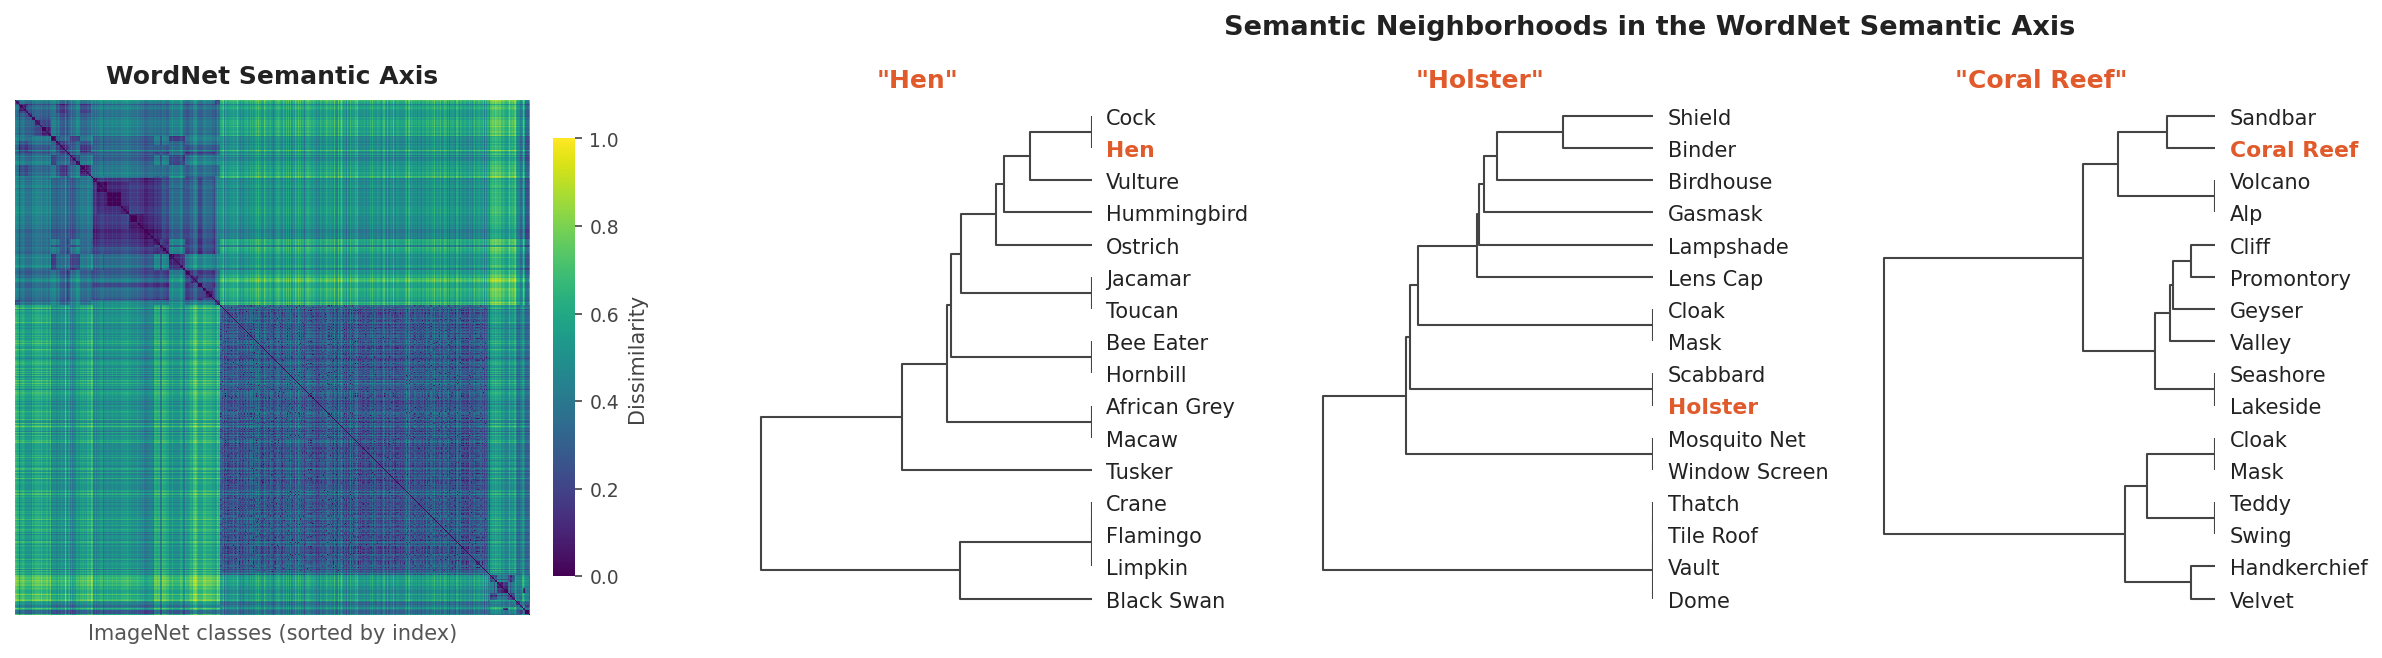

In [9]:
hen = CLASS_LABELS.index("hen")
for label in ["cock", "ostrich", "goldfish", "holster", "coral_reef"]:
    print(f"hen -> {label:12s} {hops[hen, CLASS_LABELS.index(label)]:.0f} hops")

fig = plot_rdm_with_dendrograms(wordnet, "WordNet Semantic Axis", CLASS_LABELS, FOCAL_CLASSES, show_matrix=SHOW_MATRIX)
fig.savefig(FIG_DIR / f"wordnet{suffix}.pdf", bbox_inches="tight", dpi=300)
plt.show()